<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/master/Regularisation_Mod(reg)_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.   California Housing
2.   Insurance Dataset
3.   House Prices (Kaggle)
4.   Bike Sharing Demand
4.   Energy Efficiency Dataset

Linear Regression
*     ↓
Ridge Regression
*     ↓
Lasso Regression
*     ↓
Elastic Net
*     ↓
Decision Tree Regressor
*     ↓
Random Forest Regressor
*     ↓
Gradient Boosting Regressor
*     ↓
XGBoost / LightGBM / CatBoost

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing


housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [42]:
df.shape

(20640, 9)

In [43]:
df.isna().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [44]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [45]:
df.duplicated().sum()

np.int64(0)

In [46]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


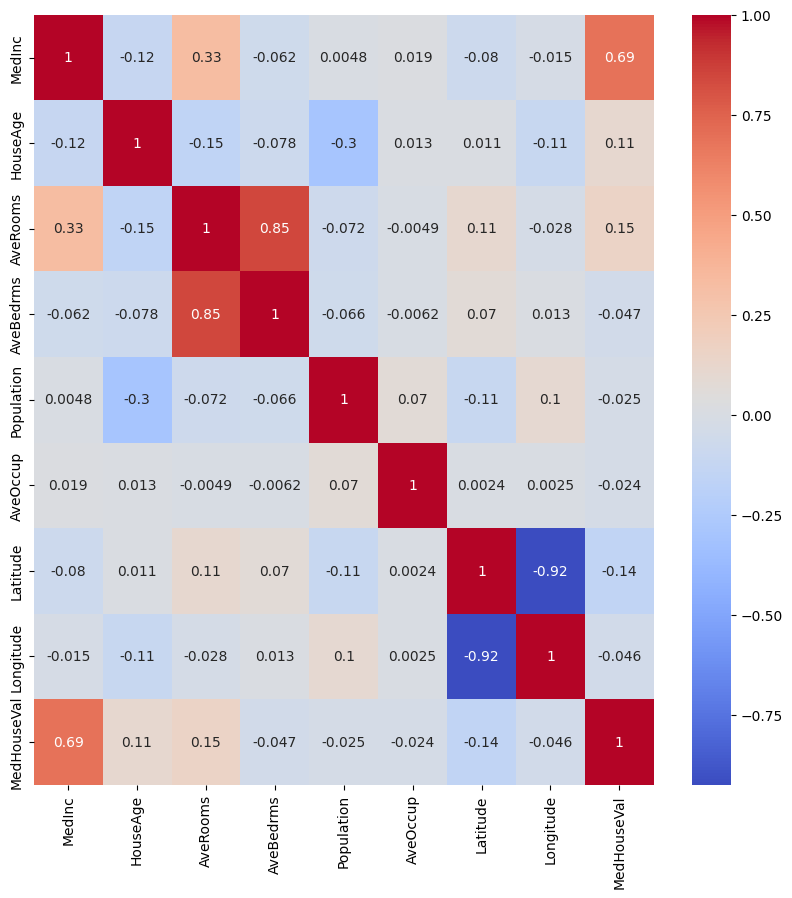

In [47]:
plt.figure(figsize=(10, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [48]:
corr = df.corr(numeric_only=True)

corr['MedHouseVal'].sort_values(ascending=False)

,MedHouseVal
MedHouseVal,1.000000
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


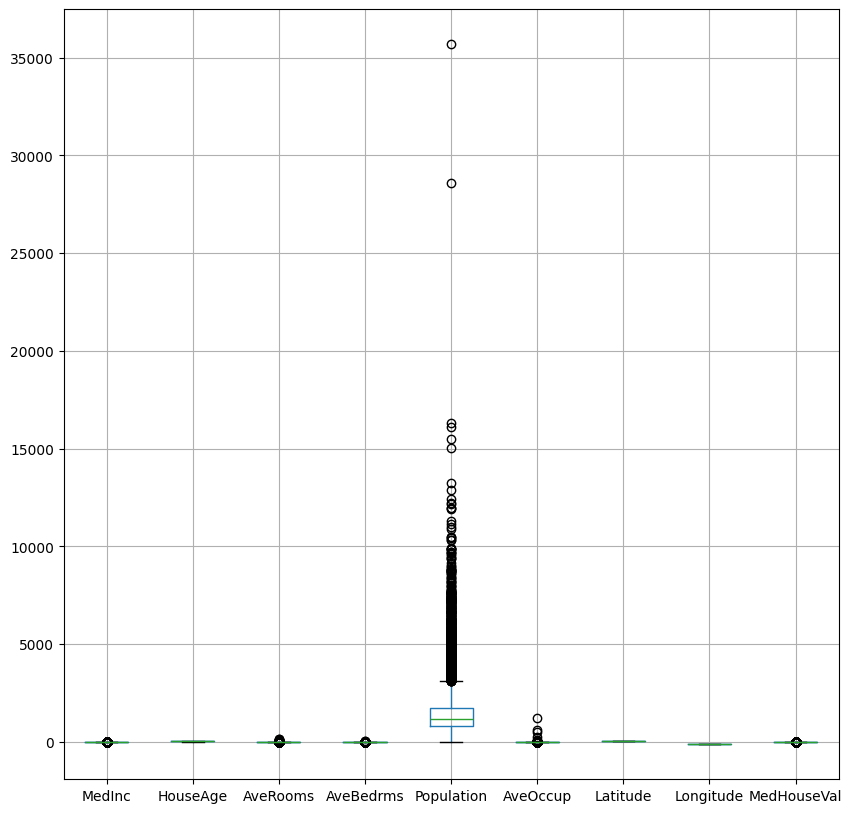

In [49]:
df.boxplot(figsize=(10, 10))
plt.show()

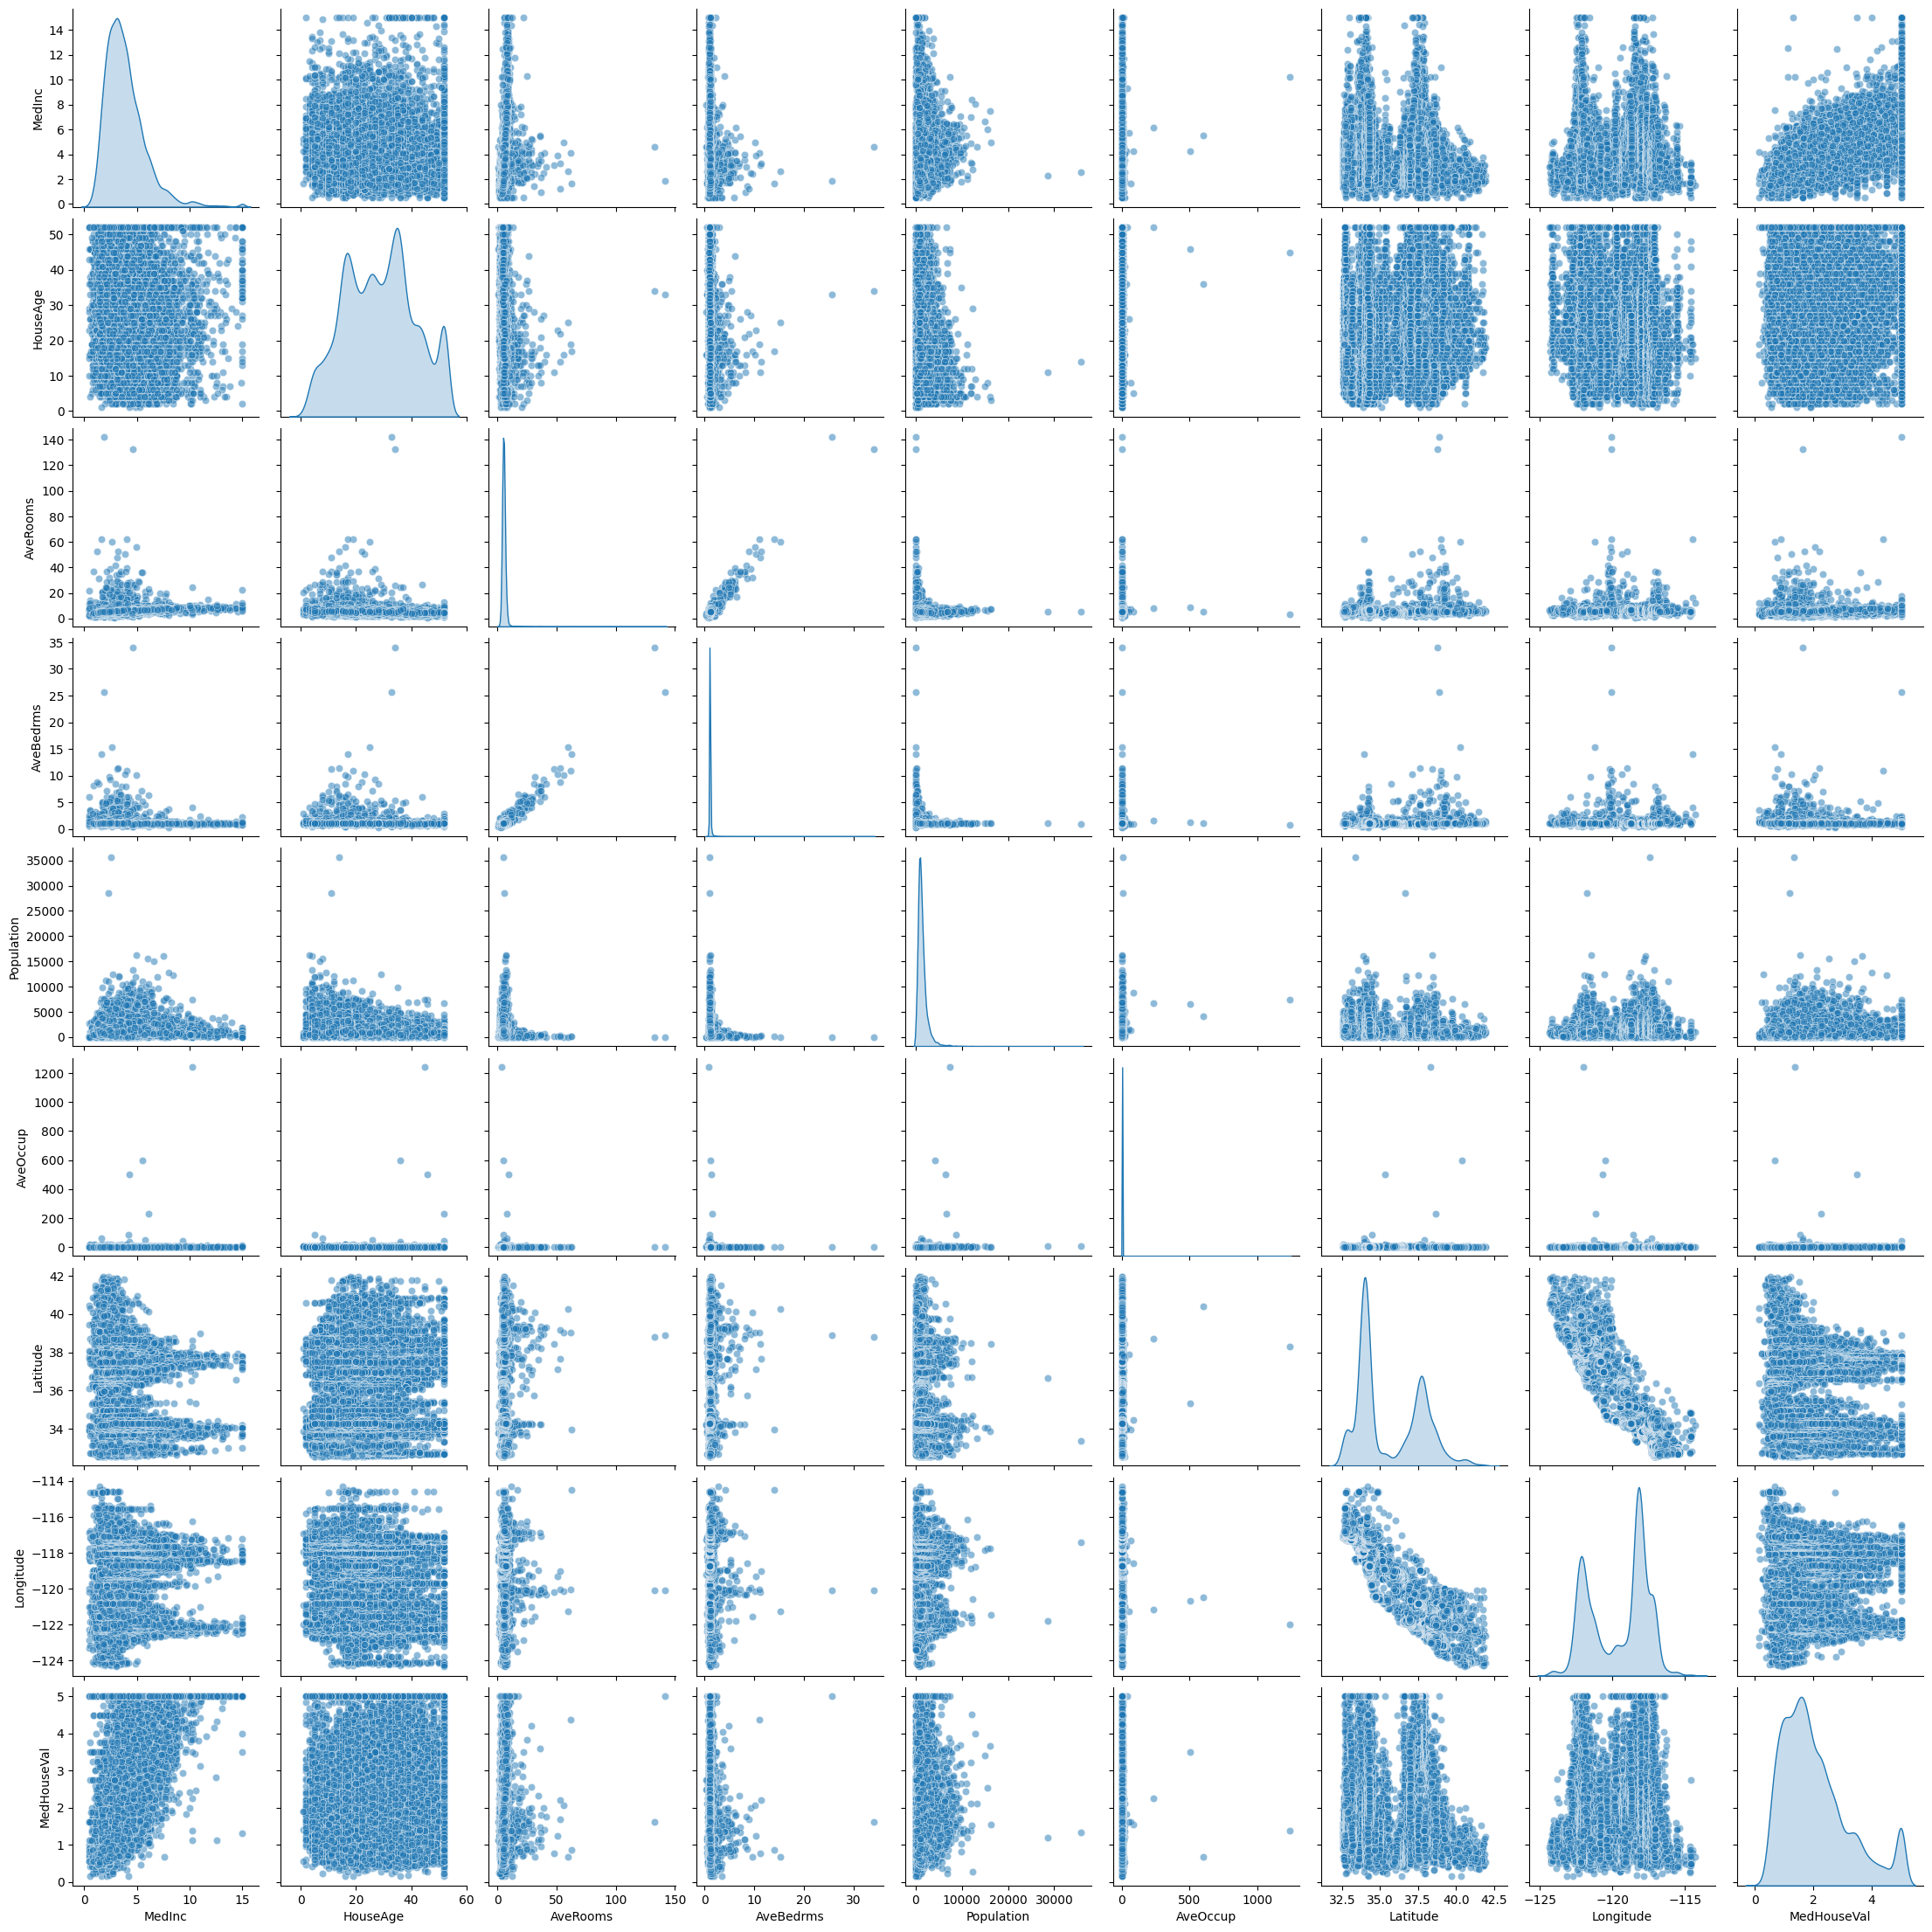

In [50]:
sns.pairplot(df,diag_kind='kde', plot_kws={'alpha': 0.5})
plt.show()

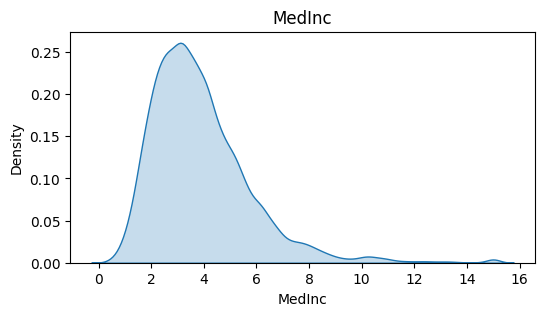

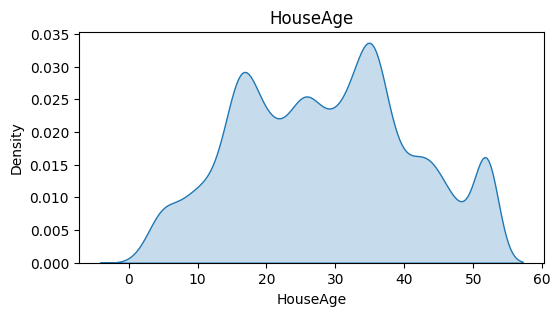

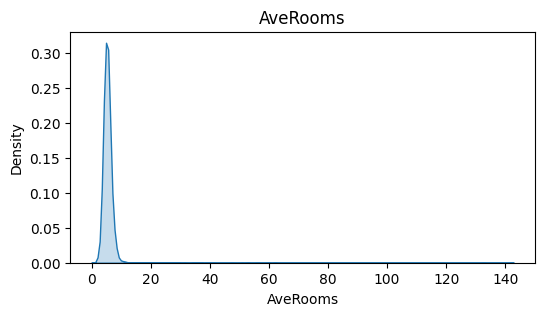

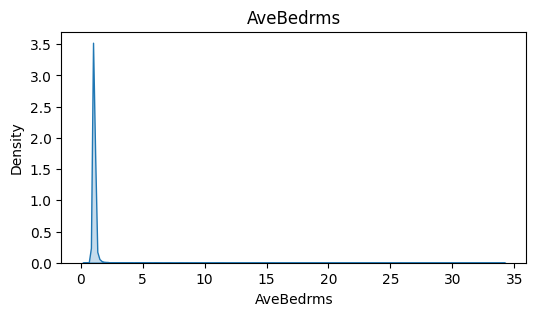

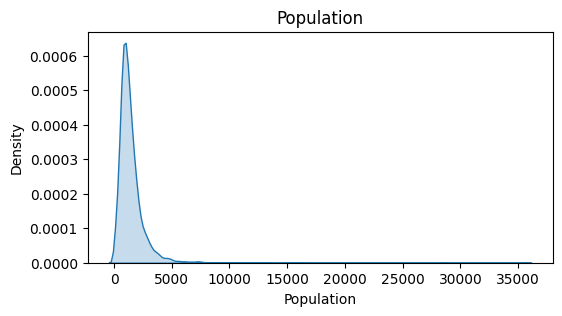

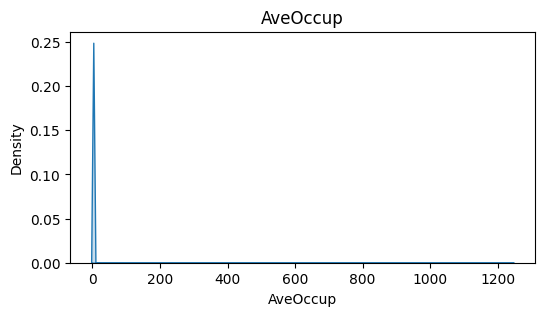

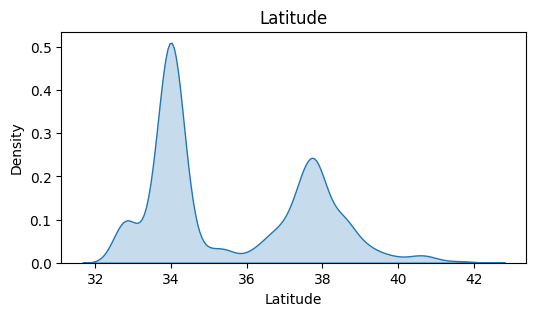

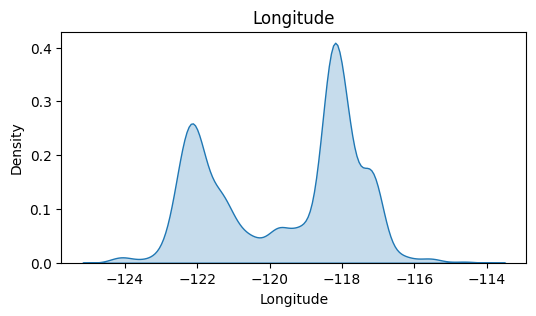

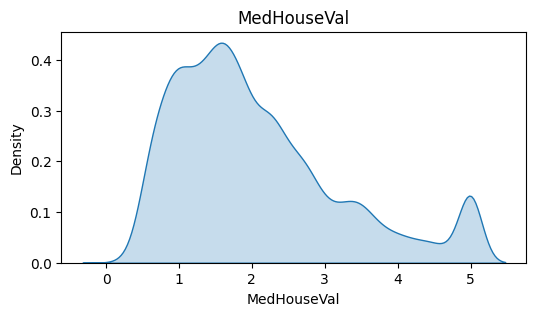

In [51]:
for col in df.columns:
    plt.figure(figsize=(6,3))
    sns.kdeplot(df[col], fill=True)
    plt.title(col)
    plt.show()

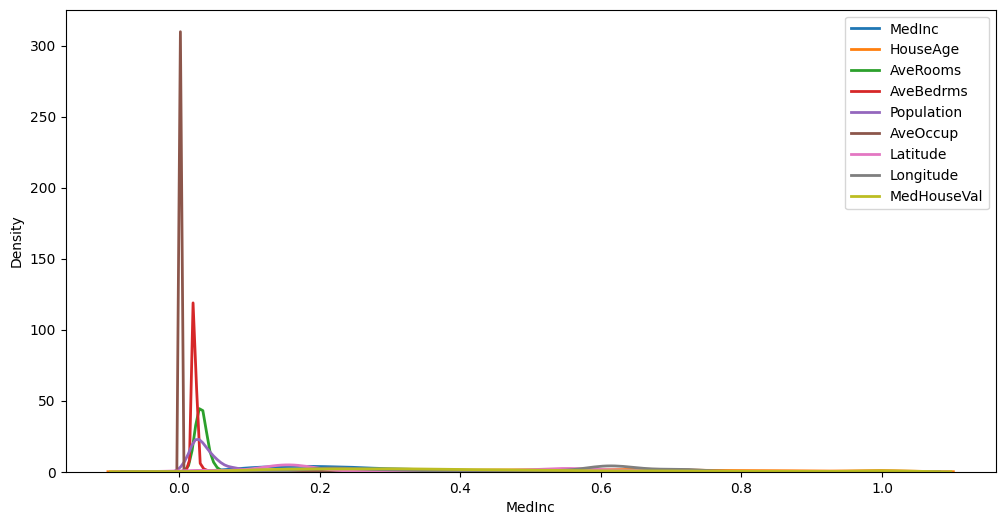

In [52]:
from sklearn.preprocessing import MinMaxScaler
# 1. Scale the data to a 0-1 range so they share the same X-axis
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# 2. Plot all the KDE (bell curves) in one single plot
plt.figure(figsize=(12, 6))

for col in df_scaled.columns:
    sns.kdeplot(df_scaled[col], label=col, fill=False, linewidth=2)
plt.legend()
plt.show()

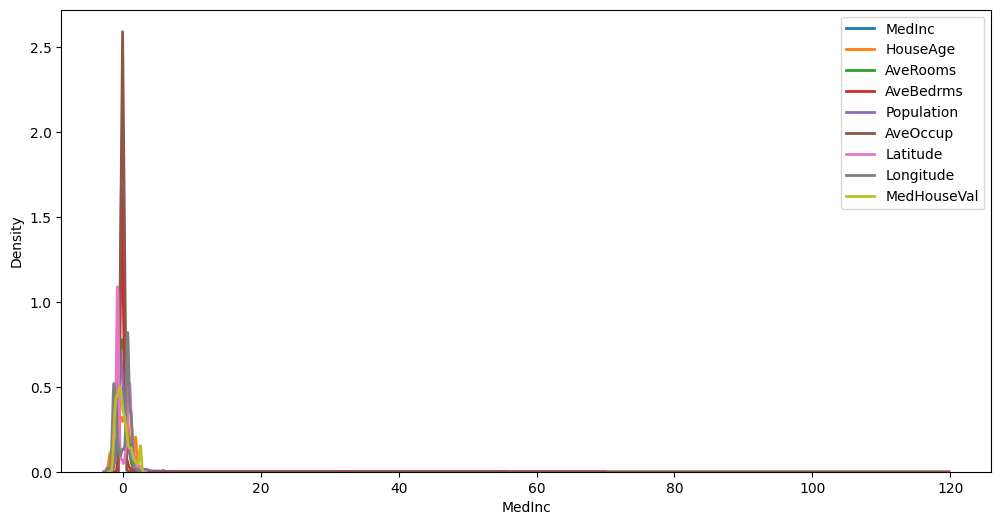

In [53]:
from sklearn.preprocessing import StandardScaler

# 1. Standardize the data to mean=0, std=1
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# 2. Plot all the KDE (bell curves) in one single plot
plt.figure(figsize=(12, 6))

for col in df_scaled.columns:
    sns.kdeplot(df_scaled[col], label=col, fill=False, linewidth=2)
plt.legend()
plt.show()

In [54]:
X=df_scaled.drop('MedHouseVal',axis=1)
y=df_scaled['MedHouseVal']

In [55]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [56]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
lr=LinearRegression()
lr.fit(X_train,y_train)
y_pred=lr.predict(X_test)

In [57]:
r2=r2_score(y_test,y_pred)
print("r2 :", r2)

r2 : 0.575787706032451


Testing error

In [58]:
m2_error_test=mean_squared_error(y_test,y_pred)
print("m2_error_test :", m2_error_test)

m2_error_test : 0.41747698052494986


In [59]:
#trainimg error
y_pred_train=lr.predict(X_train)
m2_error_train=mean_squared_error(y_train,y_pred_train)
print("m2_error_train :", m2_error_train)

m2_error_train : 0.38897000398171144


In [60]:
###Ridge
from sklearn.linear_model import Ridge
ridge=Ridge()
ridge.fit(X_train,y_train)
y_pred=ridge.predict(X_test)

#testing error
Ridge_m2_error_test=mean_squared_error(y_test,y_pred)
print("Ridge_m2_error_test :", Ridge_m2_error_test)

#trainimg error
y_pred_train=ridge.predict(X_train)
Ridge_m2_error_train=mean_squared_error(y_train,y_pred_train)
print("Ridge_m2_error_train :", Ridge_m2_error_train)

#R2 score.
Ridge_r2=r2_score(y_test,y_pred)
print("Ridge_r2 :", Ridge_r2)

Ridge_m2_error_test : 0.4174466414844415
Ridge_m2_error_train : 0.38897007566541536
Ridge_r2 : 0.5758185345441325


In [61]:
###Lasso
from sklearn.linear_model import Lasso
laso=Lasso()
laso.fit(X_train,y_train)
y_pred=laso.predict(X_test)

#testing error
laso_m2_error_test=mean_squared_error(y_test,y_pred)
print("laso_m2_error_test :", laso_m2_error_test)

#trainimg error
y_pred_train=laso.predict(X_train)
laso_m2_error_train=mean_squared_error(y_train,y_pred_train)
print("laso_m2_error_train :", laso_m2_error_train)

#R2 score.
laso_r2=r2_score(y_test,y_pred)
print("laso_r2 :", laso_r2)

laso_m2_error_test : 0.9843383850564337
laso_m2_error_train : 1.0039261841684073
laso_r2 : -0.0002190871459244459


In [62]:
##Elastic Net
from sklearn.linear_model import ElasticNet
elastic_net=ElasticNet()
elastic_net.fit(X_train,y_train)
y_pred=elastic_net.predict(X_test)

#testing error
elastic_net_m2_error_test=mean_squared_error(y_test,y_pred)
print("elastic_net_m2_error_test :", elastic_net_m2_error_test)

#trainimg error
y_pred_train=elastic_net.predict(X_train)
elastic_net_m2_error_train=mean_squared_error(y_train,y_pred_train)
print("elastic_net_m2_error_train :", elastic_net_m2_error_train)

#R2 score.
elastic_net_r2=r2_score(y_test,y_pred)
print("elastic_net_r2 :", elastic_net_r2)

elastic_net_m2_error_test : 0.8291982025622058
elastic_net_m2_error_train : 0.8420503609760025
elastic_net_r2 : 0.15742403037319197


In [63]:
# ?Ridge

In [64]:
from sklearn.model_selection import GridSearchCV

ridge=Ridge()
parameters={'alpha':[1e-15,1e-10,1e-8,1e-3,1e-2,1,5,10,20,3,50,100], "solver":["auto","svd"]}

ridge_regressor=GridSearchCV(ridge,parameters,scoring='neg_mean_squared_error',cv=5)
ridge_regressor.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [1e-15, 1e-10, 1e-08, 0.001, 0.01, 1, 5, 10,
                                   20, 3, 50, 100],
                         'solver': ['auto', 'svd']},
             scoring='neg_mean_squared_error')

In [65]:
ridge_regressor.best_estimator_

Ridge(alpha=1, solver='svd')

In [66]:
###Ridge
from sklearn.linear_model import Ridge
ridge=Ridge(alpha=1, solver='svd')
ridge.fit(X_train,y_train)
y_pred=ridge.predict(X_test)

#testing error
Ridge_m2_error_test=mean_squared_error(y_test,y_pred)
print("Ridge_m2_error_test :", Ridge_m2_error_test)

#trainimg error
y_pred_train=ridge.predict(X_train)
Ridge_m2_error_train=mean_squared_error(y_train,y_pred_train)
print("Ridge_m2_error_train :", Ridge_m2_error_train)

#R2 score.
Ridge_r2=r2_score(y_test,y_pred)
print("Ridge_r2 :", Ridge_r2)

Ridge_m2_error_test : 0.4174466414844417
Ridge_m2_error_train : 0.38897007566541536
Ridge_r2 : 0.5758185345441322


In [67]:
###Ridge

#iqr method
Q1=df.quantile(0.25)
Q3=df.quantile(0.75)
IQR=Q3-Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[~((df < (Q1 - 1.5 * IQR)) |(df > (Q3 + 1.5 * IQR))).any(axis=1)]

df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

X=df_scaled.drop(['MedHouseVal'], axis=1)
y=df['MedHouseVal']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

ridge=Ridge(alpha=1, solver='svd')
ridge.fit(X_train,y_train)
y_pred=ridge.predict(X_test)

#testing error
Ridge_m2_error_test=mean_squared_error(y_test,y_pred)
print("Ridge_m2_error_test :", Ridge_m2_error_test)

#trainimg error
y_pred_train=ridge.predict(X_train)
Ridge_m2_error_train=mean_squared_error(y_train,y_pred_train)
print("Ridge_m2_error_train :", Ridge_m2_error_train)

#R2 score.
Ridge_r2=r2_score(y_test,y_pred)
print("Ridge_r2 :", Ridge_r2)

Ridge_m2_error_test : 0.3165044650843842
Ridge_m2_error_train : 0.32339867443888776
Ridge_r2 : 0.6379168144928214
